In [340]:
import pandas as pd
from sklearn.preprocessing import  LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score

In [341]:
df1= pd.read_csv(r'C:\Users\MINE\Desktop\Customer Segmentation\data\df.csv')

In [342]:
df1.head()

,Unnamed: 0,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,0,69,Graduation,Single,58138.0,1617,25,7,0
1,1,72,Graduation,Single,46344.0,27,6,5,0
2,2,61,Graduation,Together,71613.0,776,21,4,0
3,3,42,Graduation,Together,26646.0,53,8,6,0
4,4,45,PhD,Married,58293.0,422,19,5,0


In [343]:
df1.drop(columns=['Unnamed: 0'], inplace=True)

In [344]:
df= df1.copy()

In [345]:
le1= LabelEncoder()
le2= LabelEncoder()

df1['Education']= le1.fit_transform(df1['Education'])
df1['Marital_Status']= le2.fit_transform(df1['Marital_Status'])

In [346]:
df1.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign
0,69,2,4,58138.0,1617,25,7,0
1,72,2,4,46344.0,27,6,5,0
2,61,2,5,71613.0,776,21,4,0
3,42,2,5,26646.0,53,8,6,0
4,45,4,3,58293.0,422,19,5,0


In [347]:
joblib.dump(le1, r'C:\Users\MINE\Desktop\Customer Segmentation\model\le1.pkl')
joblib.dump(le2, r'C:\Users\MINE\Desktop\Customer Segmentation\model\le2.pkl')

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\model\\le2.pkl']

In [348]:
scale= StandardScaler()
x= scale.fit_transform(df1)

In [349]:
joblib.dump(scale, r'C:\Users\MINE\Desktop\Customer Segmentation\model\scaler.pkl')

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\model\\scaler.pkl']

In [350]:
x

array([[ 1.01959441, -0.35052725,  0.25421812, ...,  1.31944644,
         0.69323197, -0.43926491],
       [ 1.27623017, -0.35052725,  0.25421812, ..., -1.15798724,
        -0.1315745 , -0.43926491],
       [ 0.33523239, -0.35052725,  1.18230273, ...,  0.79788146,
        -0.54397773, -0.43926491],
       ...,
       [-1.03349166, -0.35052725, -1.60195109, ...,  0.53709896,
         0.28082874,  1.03336905],
       [ 1.10513966,  0.53924181,  1.18230273, ...,  1.05866395,
        -0.95638097, -0.43926491],
       [ 1.27623017,  1.42901088, -0.67386649, ..., -0.50603101,
         0.69323197, -0.43926491]])

In [351]:
clusters= list(range(2,11))
scores= []
ss_score= []

for i in clusters:
  model= KMeans(n_clusters=i)
  label= model.fit_predict(x)
  scores.append(model.inertia_)
  ss_score.append(silhouette_score(x, label))
 

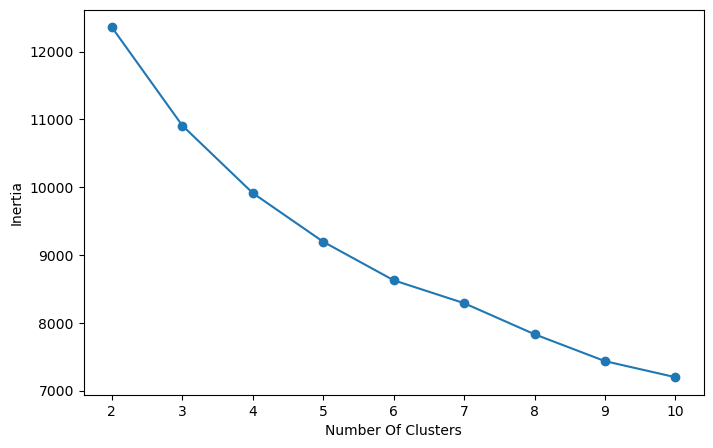

In [352]:
plt.figure(figsize=(8,5))

plt.plot(clusters, scores, marker='o')

plt.xlabel('Number Of Clusters')
plt.ylabel('Inertia')

plt.show()

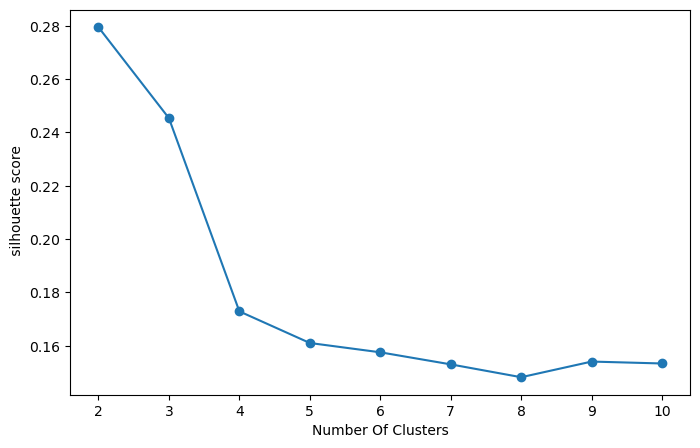

In [353]:
plt.figure(figsize=(8,5))

plt.plot(clusters, ss_score, marker='o')

plt.xlabel('Number Of Clusters')
plt.ylabel(' silhouette score')

plt.show()

In [354]:
k_means_model= KMeans(n_clusters=4, n_init=20, random_state=42,)

In [355]:
df['cluster']= k_means_model.fit_predict(x)

In [356]:
df.head()

,age,Education,Marital_Status,Income,amount_spent,purchases,NumWebVisitsMonth,campaign,cluster
0,69,Graduation,Single,58138.0,1617,25,7,0,2
1,72,Graduation,Single,46344.0,27,6,5,0,1
2,61,Graduation,Together,71613.0,776,21,4,0,2
3,42,Graduation,Together,26646.0,53,8,6,0,0
4,45,PhD,Married,58293.0,422,19,5,0,1


In [357]:
df['cluster'].value_counts()

cluster
2    768
0    632
1    605
3    211
Name: count, dtype: int64

In [358]:
centroid= k_means_model.cluster_centers_
centroid= scale.inverse_transform(centroid)

In [359]:
centroid

array([[4.87167722e+01, 1.61550633e+00, 3.71202532e+00, 3.11946851e+04,
        1.16615506e+02, 8.33386076e+00, 6.83227848e+00, 7.59493671e-02],
       [6.25586777e+01, 3.11900826e+00, 3.72892562e+00, 4.27178967e+04,
        2.02385124e+02, 1.08148760e+01, 6.13719008e+00, 1.35537190e-01],
       [6.01458333e+01, 2.43619792e+00, 3.72395833e+00, 6.75833314e+04,
        1.05051823e+03, 2.18151042e+01, 4.00260417e+00, 1.60156250e-01],
       [5.52748815e+01, 2.49289100e+00, 3.76777251e+00, 8.03543033e+04,
        1.62245024e+03, 2.09099526e+01, 3.23222749e+00, 1.93364929e+00]])

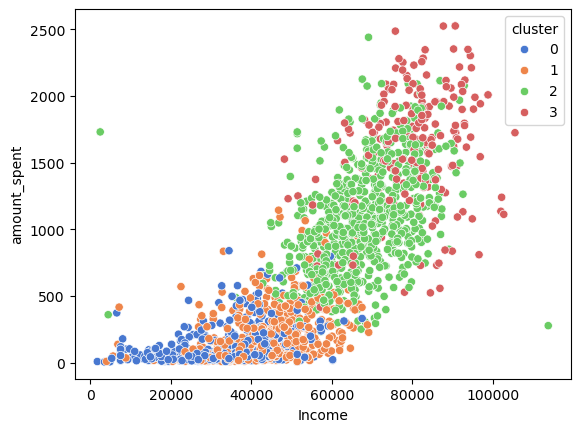

In [360]:
sns.scatterplot(data=df, x='Income', y='amount_spent', hue='cluster',palette='muted')


plt.show()

In [361]:
pca=PCA().fit(x)

In [362]:
pca.explained_variance_ratio_

array([0.39563462, 0.14489571, 0.12481478, 0.11047126, 0.09641138,
       0.08502293, 0.02420037, 0.01854894])

In [363]:
pca= PCA(n_components=2).fit(x)
xpca= pca.transform(x)

In [364]:
df['x'],df['y']= xpca[:,0],xpca[:,1]

In [377]:
joblib.dump(pca, r'C:\Users\MINE\Desktop\Customer Segmentation\model\pca.pkl')

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\model\\pca.pkl']

In [365]:
center= pca.transform(k_means_model.cluster_centers_)

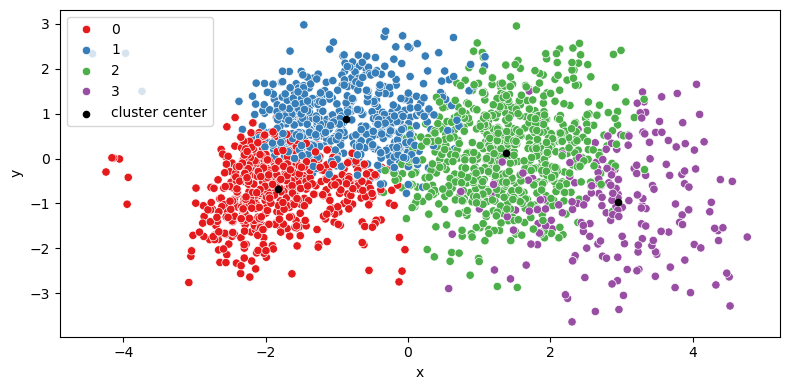

In [366]:
plt.figure(figsize=(8,4))

sns.scatterplot(data= df, x='x', y='y', hue='cluster', palette='Set1')

plt.scatter(center[:,0], center[:,1] ,color='black', label='cluster center', s=20)

plt.tight_layout()
plt.legend(loc='best')
plt.show()

In [367]:
features= df.drop(columns=['cluster', 'Education', 'Marital_Status']).columns
cluster_features= df.groupby('cluster')[features].agg(['mean','sum'])

In [376]:
round(cluster_features,2)

age           Income             amount_spent         purchases  \
          mean    sum      mean         sum         mean     sum      mean   
cluster                                                                      
0        48.72  30789  31194.69  19715041.0       116.62   73701      8.33   
1        62.56  37848  42717.90  25844327.5       202.39  122443     10.81   
2        60.15  46192  67583.33  51903998.5      1050.52  806798     21.82   
3        55.27  11663  80354.30  16954758.0      1622.45  342337     20.91   

               NumWebVisitsMonth       campaign          x              y  \
           sum              mean   sum     mean  sum  mean      sum  mean   
cluster                                                                     
0         5267              6.83  4318     0.08   48 -1.83 -1154.23 -0.69   
1         6543              6.14  3713     0.14   82 -0.87  -529.05  0.89   
2        16754              4.00  3074     0.16  123  1.38  1060.10  0.13   
3         4412              3.23   682     1.93  408  2.95   623.18 -0.96   

                 
            sum  
cluster          
0       -433.22  
1        536.18  
2        100.03  
3       -202.99

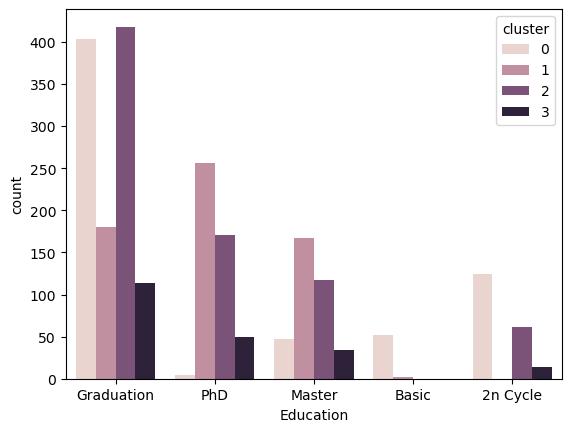

In [369]:
sns.countplot(data=df, x='Education', hue='cluster')

plt.show()

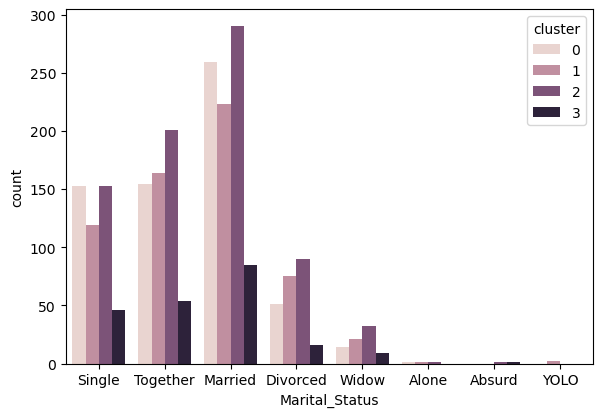

In [371]:
plt.figure(figsize=(6.8,4.6))
sns.countplot(data=df, x='Marital_Status', hue='cluster')

plt.show()

In [373]:
df[['cluster','Marital_Status','Education']].value_counts().unstack(-1)

Education               2n Cycle  Basic  Graduation  Master   PhD
cluster Marital_Status                                           
0       Alone                NaN    NaN         1.0     NaN   NaN
        Divorced            13.0    1.0        34.0     3.0   NaN
        Married             51.0   19.0       168.0    19.0   2.0
        Single              23.0   18.0        99.0    12.0   1.0
        Together            34.0   13.0        92.0    13.0   2.0
        Widow                3.0    1.0        10.0     NaN   NaN
1       Alone                NaN    NaN         NaN     NaN   1.0
        Divorced             NaN    NaN        25.0    20.0  30.0
        Married              NaN    1.0        63.0    63.0  96.0
        Single               NaN    NaN        32.0    30.0  57.0
        Together             NaN    1.0        55.0    48.0  60.0
        Widow                NaN    NaN         5.0     6.0  10.0
        YOLO                 NaN    NaN         NaN     NaN   2.0
2       Absurd               NaN    NaN         NaN     1.0   NaN
        Alone                NaN    NaN         NaN     1.0   NaN
        Divorced             8.0    NaN        51.0    13.0  18.0
        Married             24.0    NaN       153.0    46.0  67.0
        Single               8.0    NaN        96.0    21.0  28.0
        Together            20.0    NaN       101.0    33.0  47.0
        Widow                2.0    NaN        17.0     2.0  11.0
3       Absurd               NaN    NaN         1.0     NaN   NaN
        Divorced             2.0    NaN         9.0     1.0   4.0
        Married              5.0    NaN        45.0    10.0  25.0
        Single               5.0    NaN        19.0    12.0  10.0
        Together             2.0    NaN        37.0     8.0   7.0
        Widow                NaN    NaN         3.0     3.0   3.0

In [374]:
joblib.dump(k_means_model, r'C:\Users\MINE\Desktop\Customer Segmentation\model\k_means.pkl')

['C:\\Users\\MINE\\Desktop\\Customer Segmentation\\model\\k_means.pkl']

> INSIGHT

* Cluster 1 are the oldest in the group, they are the second smallest income earners,they rank second to last in the amount spent and number of purchases, they visit the web the most and are mostly PHD holders they are also mostly married

* Cluster 0 are the youngest, most are marriedand single with graduation educational status, phd holders are not in this category,they rank last in amount spent and number of purchases, they tend to visit the web a lot and they do no take campaigns

* Cluater 2 are the second highest spenders, they are mostly married or together most are graduate holders, they make the most purchases and visit the web frequently

* Cluster 3 are below the median age, they spend the most and also makes the most money, they accepted campaign the most, majourity of them are married with graduation